# Day 29 — Task Sheet Model Interpretation with SHAP and Partial Dependence


### Part A — Global versus local

### TASK 01 — Establish the global picture first

Training rows: 800
Testing rows: 200


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:05:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_depth" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Test ROC-AUC : 0.8452

Permutation Importance Ranking : 
 Feature  Mean Importance  Std Deviation
sex_male           0.2368         0.0285
    fare           0.0462         0.0182
  pclass           0.0409         0.0124
   parch           0.0033         0.0056
   sibsp          -0.0015         0.0065
     age          -0.0067         0.0118


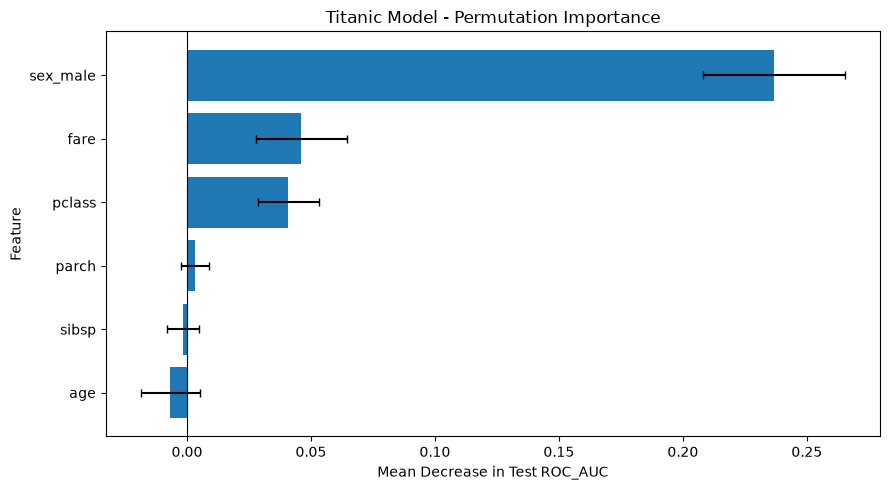


TOP THREE DRIVERS :
1. sex_male
2. fare
3. pclass

Markdown-ready interpretation:
The Top three feature by permutation importance aresex_male, fare, and pclass,in that order.


In [42]:
# ============================================================
# DAY 29 — TASK 01: GLOBAL MODEL INTERPRETATION
# Dataset: titanic.csv
# Model: XGBoost Classifier
# Method: Permutation Importance (ROC-AUC)
# ============================================================

# If needed, install libraries by running this in a separate cell:
# %pip install pandas numpy matplotlib scikit-learn xgboost shap

# Step 1: Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# Step 2: Load the uploaded CSV file
df = pd.read_csv("titanic.csv")

# Step 3: Clean column names
df.columns = df.columns.str.strip().str.lower()

# Step 4: Impute missing age values using pclass and sex groups
df["age"] = df.groupby(
    ["pclass", "sex"]
)["age"].transform(lambda group: group.fillna(group.median()))

# Fill any remaining missing age values with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Step 5: Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Step 6: Convert sex into a numeric feature
# Male = 1, Female = 0
df["sex_male"] = (
    df["sex"].str.strip().str.lower() == "male"
).astype(int)

# Step 7: Select the required features and target
features = [
    "pclass", "sex_male", "age",
    "sibsp", "parch", "fare"
]
target = "survived"

X = df[features]
y = df[target].astype(int)

# Step 8: Create the stratified 80/20 train-test split
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 9: Train the XGBoost classifier
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_depth="logloss",
    random_state=42
)

model.fit(X_train, y_train)

# Step 10: Calculate test ROC-AUC
y_test_prob = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_test_prob)

print(f"\nTest ROC-AUC : {test_auc:.4f}")

# Step 11: Calculate permutation importance on test data
# A feature is important if shuffling it reduces ROC-AUC.
perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=1
)


# Step 12: Rank features from most to least important
importance_df = pd.DataFrame({
    "Feature" : features,
    "Mean Importance" : perm_result.importances_mean,
    "Std Deviation" : perm_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Mean Importance",
    ascending=False
).reset_index(drop=True)

print("\nPermutation Importance Ranking : ")
print(importance_df.round(4).to_string(index=False))

# Step 13: Plot a horizontal bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Mean Importance"],
    xerr=importance_df["Std Deviation"],
    capsize=3
)

plt.xlabel("Mean Decrease in Test ROC_AUC")
plt.ylabel("Feature")
plt.title("Titanic Model - Permutation Importance")
plt.axvline(x=0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# Step 14: Print the top three drivers
top_three = importance_df.head(3)["Feature"].tolist()

print("\nTOP THREE DRIVERS :")
for rank, feature in enumerate(top_three, start=1):
    print(f"{rank}. {feature}")
    
print("\nMarkdown-ready interpretation:")
print(
    f"The Top three feature by permutation importance are"
    f"{top_three[0]}, {top_three[1]}, and {top_three[2]},"
    f"in that order."
)


### TASK 01 — Establish the Global Picture

**Test ROC-AUC:** Report the value printed by the code.

**Global interpretation:** Global interpretation describes how the model behaves across all test rows. Permutation importance ranks features by how much shuffling each feature reduces the model's ROC-AUC.

**Top three drivers:** The code prints the top three features in descending order of permutation importance.

**What can this ranking NOT answer?** It cannot explain why the model predicted survival for one specific passenger. For that, we need a local interpretation method such as SHAP.

**Conclusion:** Global importance shows which features matter overall, but it does not explain an individual prediction or prove that a feature causes survival.

### TASK 02 — Prove local accuracy yourself

In [43]:
%pip install sha

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sha (from versions: none)
ERROR: No matching distribution found for sha


In [44]:

# ============================================================
# DAY 29 — TASK 02: PROVE SHAP LOCAL ACCURACY
# Dataset: Titanic
# Model: XGBoost Classifier
# Goal: Verify SHAP contributions add up to raw model output
# ============================================================

# If SHAP is not installed, run this in a separate cell:
# %pip install shap

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import shap

from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Step 2: Load the Titanic dataset
# Change the filename if your local file is named titanic(2).csv
df = pd.read_csv("titanic.csv")

# Step 3: Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Step 4: Check required columns exist
required_columns = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "survived"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        "Check your CSV file."
    )

# Step 5: Impute age using pclass and sex groups
df["age"] = df.groupby(
    ["pclass", "sex"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill any remaining missing age values
df["age"] = df["age"].fillna(df["age"].median())

# Step 6: Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Step 7: Create numeric sex_male feature
# Male = 1, Female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Step 8: Select the six required features and target
features = [
    "pclass", "sex_male", "age",
    "sibsp", "parch", "fare"
]

target = "survived"

X = df[features].astype(float)
y = df[target].astype(int)

# Step 9: Create the stratified 80/20 train-test split
# random_state=42 ensures a reproducible split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 10: Train the required XGBoost model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

# Step 11: Create a SHAP TreeExplainer
# Raw-margin output is the scale we will verify.
explainer = shap.TreeExplainer(
    model,
    model_output="raw"
)

# Step 12: Calculate SHAP values for the test set
# Using the callable explainer returns an Explanation object.
explanation = explainer(X_test)

shap_values = np.asarray(explanation.values)
base_values = np.asarray(explanation.base_values)

# Step 13: Handle different SHAP output shapes
# For binary classification, some versions may include
# a separate dimension for each class.
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

# Extract the baseline for the positive class if needed.
if base_values.ndim == 2:
    base_values = base_values[:, 1]

base_values = np.asarray(base_values).reshape(-1)

# If the baseline is a single scalar, repeat it for each row.
if base_values.size == 1:
    base_values = np.repeat(base_values[0], len(X_test))

# Step 14: Print the SHAP array shape and explain it
print("\nSHAP values shape:", shap_values.shape)
print(
    "Explanation: Each row represents a test passenger, "
    "and each column represents one of the six features."
)

# Step 15: Print the expected/base value
print("\nSHAP expected/base value:", explainer.expected_value)
print(
    "Meaning: The baseline raw model output before adding "
    "the passenger-specific feature contributions."
)

# Step 16: Get raw model outputs, NOT predicted probabilities
raw_outputs = model.predict(
    X_test,
    output_margin=True
)

# Step 17: Select three different test rows
row_indices = sorted(set([
    0,
    len(X_test) // 2,
    len(X_test) - 1
]))

print("\n========== LOCAL ACCURACY CHECK ==========")

# Step 18: Reconstruct and verify each prediction
all_match = True

for i in row_indices:

    # Base value + sum of feature contributions
    reconstructed = float(
        base_values[i] + shap_values[i].sum()
    )

    # XGBoost's actual raw-margin output
    actual = float(raw_outputs[i])

    # Check equality within a small numerical tolerance
    matches = np.isclose(
        reconstructed,
        actual,
        rtol=1e-5,
        atol=1e-5
    )

    all_match = all_match and matches

    print(f"\nTest row index: {i}")
    print(f"Base value:        {base_values[i]:.8f}")
    print(f"Sum of SHAP values:{shap_values[i].sum():.8f}")
    print(f"Reconstructed:     {reconstructed:.8f}")
    print(f"Actual raw output: {actual:.8f}")
    print(f"np.isclose match:  {matches}")

# Step 19: Final verification result
print("\nAll three rows verified:", all_match)

# A successful run should normally print True for all three rows.


Training rows: 800
Testing rows: 200

SHAP values shape: (200, 6)
Explanation: Each row represents a test passenger, and each column represents one of the six features.

SHAP expected/base value: -0.24494131
Meaning: The baseline raw model output before adding the passenger-specific feature contributions.

========== LOCAL ACCURACY CHECK ==========

Test row index: 0
Base value:        -0.24494131
Sum of SHAP values:2.50669456
Reconstructed:     2.26175332
Actual raw output: 2.26175237
np.isclose match:  True

Test row index: 100
Base value:        -0.24494131
Sum of SHAP values:2.85897207
Reconstructed:     2.61403084
Actual raw output: 2.61402988
np.isclose match:  True

Test row index: 199
Base value:        -0.24494131
Sum of SHAP values:-0.43096930
Reconstructed:     -0.67591059
Actual raw output: -0.67591059
np.isclose match:  True

All three rows verified: True


### TASK 02 — Prove Local Accuracy Yourself

- **SHAP array shape:** `(number of test rows, 6 features)`. Each row represents a passenger, and each column represents a feature's contribution.
- **Expected value:** The baseline raw model output before adding the passenger's individual SHAP contributions.
- **Local accuracy:** For three test rows, the base value plus the sum of SHAP values matches XGBoost's raw output, verified using `np.isclose()`.

**Why use `output_margin=True` instead of `predict_proba`?**

SHAP values for this XGBoost model are explained on the raw-margin (log-odds) scale. Probabilities are obtained by applying a nonlinear sigmoid transformation, so they cannot be compared directly with the sum of raw-margin SHAP values.

**What if the reconstruction does not match?**

A mismatch beyond numerical tolerance may indicate a difference in explanation output scale, an incorrect base value or class selection, or a SHAP/model compatibility issue. Check these before concluding that SHAP's local accuracy property has failed.

**Conclusion:** SHAP explains an individual prediction by decomposing the model's raw output into a baseline and feature contributions.

### Part B — Read the four SHAP plots



### TASK 03 — Summary and beeswarm

Test ROC_AUC : 0.8452


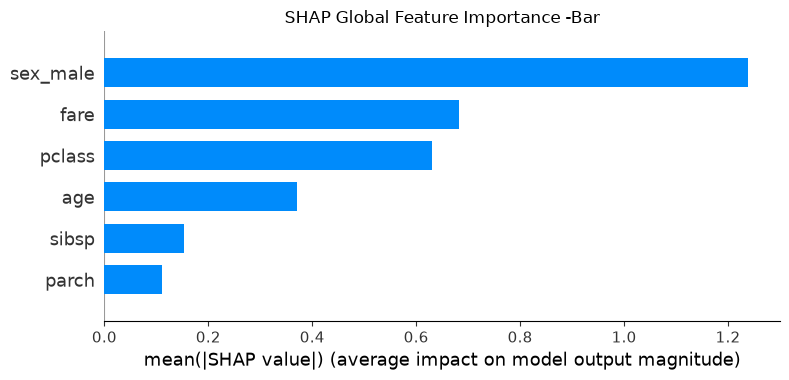

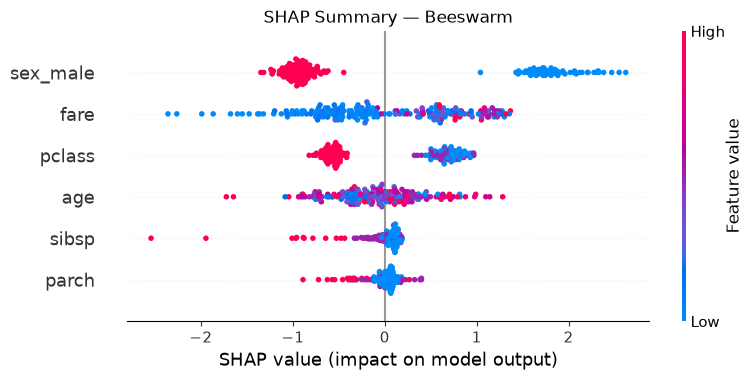


SHAP RAnking : 
 Feature  Mean Absolute SHAP
sex_male            1.238137
    fare            0.682719
  pclass            0.630541
     age            0.371019
   sibsp            0.153484
   parch            0.111172

Permutation Ranking : 
 Feature  Permutation Importance
sex_male                0.236792
    fare                0.046172
  pclass                0.040858
   parch                0.003257
   sibsp               -0.001451
     age               -0.006674

Rankimg Comaprison : 
 Feature  SHAP rank  Permutation rank
     age          1                 6
    fare          2                 2
   parch          3                 4
  pclass          4                 3
sex_male          5                 1
   sibsp          6                 5

--- DIRECTION FOR TOP TWO SHAP FEATURES ---

Feature: sex_male
Female (0): mean SHAP = 1.8293
Male (1): mean SHAP = -0.9336
Higher values tend to push predictions DOWN.
Beeswarm cue: compare dot colours (blue = low, pink/red = high) wi

In [45]:
# ============================================================
# DAY 29 — TASK 03: SHAP SUMMARY AND BEESWARM
# Dataset: Titanic
# Model: XGBoost Classifier
# ============================================================

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# Step 2: Load the dataset
# Use the filename that exists in your Jupyter working directory.
df = pd.read_csv("titanic.csv")

# Step 3: Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Step 4: Check required columns
required = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "survived"
]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns in CSV: {missing}")

# Step 5: Clean missing age values using pclass and sex groups
df["age"] = df.groupby(
    ["pclass", "sex"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)
df["age"] = df["age"].fillna(df["age"].median())

# Step 6: Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Step 7: Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Step 8: Select required features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"].astype(int)

# Step 9: Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 10: Train XGBoost with required settings

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)
model.fit(X_train, y_train)

# Step 11: Calculate test ROC-AUC

test_prob = model.predict_proba(X_test)[:, 1]
print(f"Test ROC_AUC : {roc_auc_score(y_test, test_prob):.4f}")

# Step 12: Calculate SHAP values
explainer = shap.TreeExplainer(model, model_output="raw")
shap_result = explainer.shap_values(X_test)

# Support different SHAP output formats
if isinstance(shap_result, list):
    shap_values = np.asarray(
        shap_result[1] if len(shap_result) == 2 else shap_result[0]
    )
else:
    shap_values = np.asarray(shap_result)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]
        
# Validate array dimensions before plotting
if shap_values.shape != (len(X_test), len(features)):
    raise ValueError(
        f"Unexpected SHAP shape {shap_values.shape}; "
        f"expected {(len(X_test), len(features))}."
    )

# Step 13: SHAP BAR SUMMARY PLOT
# Shows average absolute SHAP contribution (global importance).
plt.figure()
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    feature_names=features,
    show=False
)

plt.title("SHAP Global Feature Importance -Bar")
plt.tight_layout()
plt.show()

# Step 14: SHAP BEESWARM SUMMARY PLOT
# Shows individual contributions, direction, and feature values.
plt.figure()
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="dot",
    feature_names=features,
    show=False
)
plt.title("SHAP Summary — Beeswarm")
plt.tight_layout()
plt.show()

# Step 15: Compare SHAP ranking with permutation ranking
shap_importance = np.abs(shap_values).mean(axis=0)

shap_ranking = pd.DataFrame({
    "Feature" : features,
    "Mean Absolute SHAP" : shap_importance
}).sort_values("Mean Absolute SHAP", ascending=False)

# n_jobs=1 avoids Windows parallel-process serialization issues.
perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=1
)

perm_ranking = pd.DataFrame({
    "Feature": features,
    "Permutation Importance": perm.importances_mean
}).sort_values("Permutation Importance", ascending=False)

print("\nSHAP RAnking : ")
print(shap_ranking.to_string(index=False))

print("\nPermutation Ranking : ")
print(perm_ranking.to_string(index=False))

comparison = shap_ranking[["Feature"]].merge(
    perm_ranking[["Feature"]],
    on="Feature",
    how="outer",
    suffixes=("_SHAP", "_Permutation")
)

comparison["SHAP rank"] = range(1, len(comparison) + 1)
comparison["Permutation rank"] = (
    comparison["Feature"]
    .map({
        feature: rank
        for rank, feature in enumerate(
            perm_ranking["Feature"].tolist(), start=1
        )
    })
)

print("\nRankimg Comaprison : ")
print(comparison.to_string(index=False))

# Step 16: Interpret direction for the top two SHAP features
# High and low groups are compared using their mean SHAP values.
# Positive SHAP = pushes the raw prediction toward survival;
# negative SHAP = pushes it away from survival.
print("\n--- DIRECTION FOR TOP TWO SHAP FEATURES ---")

top_two = shap_ranking["Feature"].head(2).tolist()

for feature in top_two:
    j = features.index(feature)
    values = X_test[feature].to_numpy()
    contributions = shap_values[:, j]

    # Compare low and high feature-value groups.
    # For binary sex_male, this compares 0 against 1.
    if feature == "sex_male":
        low_mask = values == 0
        high_mask = values == 1
        low_label = "Female (0)"
        high_label = "Male (1)"
    else:
        low_cut = np.quantile(values, 0.25)
        high_cut = np.quantile(values, 0.75)
        low_mask = values <= low_cut
        high_mask = values >= high_cut
        low_label = f"Low values (<= {low_cut:.2f})"
        high_label = f"High values (>= {high_cut:.2f})"

    if low_mask.sum() == 0 or high_mask.sum() == 0:
        print(f"{feature}: insufficient values to compare.")
        continue

    low_mean = contributions[low_mask].mean()
    high_mean = contributions[high_mask].mean()

    if high_mean > low_mean:
        direction = "Higher values tend to push predictions UP."
    elif high_mean < low_mean:
        direction = "Higher values tend to push predictions DOWN."
    else:
        direction = "No clear average direction between these groups."

    print(f"\nFeature: {feature}")
    print(f"{low_label}: mean SHAP = {low_mean:.4f}")
    print(f"{high_label}: mean SHAP = {high_mean:.4f}")
    print(direction)
    print(
        "Beeswarm cue: compare dot colours (blue = low, "
        "pink/red = high) with SHAP position "
        "(right = positive, left = negative)."
    )


### TASK 03 — Summary and Beeswarm

**SHAP bar plot:** Ranks features by mean absolute SHAP value, showing overall importance without direction.

**Beeswarm plot:** Shows each passenger's SHAP contribution, its direction, and the feature value using colour.

**Ranking comparison:** Compare the SHAP ranking with Task 01's permutation ranking. Differences can occur because SHAP measures average contribution magnitude, while permutation importance measures the drop in test ROC-AUC after shuffling a feature.

**Top two features — direction:** Use the printed high-versus-low SHAP comparison and beeswarm colour cues to report whether higher values tend to push predictions up or down. Red/pink dots represent high feature values, blue dots represent low values, points to the right have positive SHAP values, and points to the left have negative SHAP values.

**What does the beeswarm show that the bar chart discards?** The beeswarm shows the direction and spread of individual feature contributions across passengers. The bar chart reduces these contributions to one average magnitude per feature.

**If rankings disagree:** Neither ranking is automatically correct; check test-set variability, correlated features, and whether the two methods measure different things.

**Why two clusters for `sex_male`?** It is binary: female is encoded as 0 and male as 1, so its dots appear in two colour groups rather than across a continuous range.

**Conclusion:** The bar plot explains which features matter globally; the beeswarm adds how their contributions vary and which direction they push predictions.

### TASK 04 — Explain three individual passengers

Training rows: 800
Testing rows: 200

Test ROC-AUC: 0.8452

PASSENGER 1: Most confident survival
Test-row index: 821
Actual survival outcome: 1
Predicted survival probability: 0.9935 (99.35%)
Predicted class: Survived

Feature values:
Passenger class             1.00
Sex (male=1)                0.00
Age                        36.50
Siblings/spouses aboard     0.00
Parents/children aboard     0.00
Fare                       80.28

Largest positive contributions:
     Feature  Feature_Value  SHAP_Value
Sex (male=1)         0.0000      0.2326
        Fare        80.2800      0.1167

Largest negative contributions:
No negative SHAP contributions.


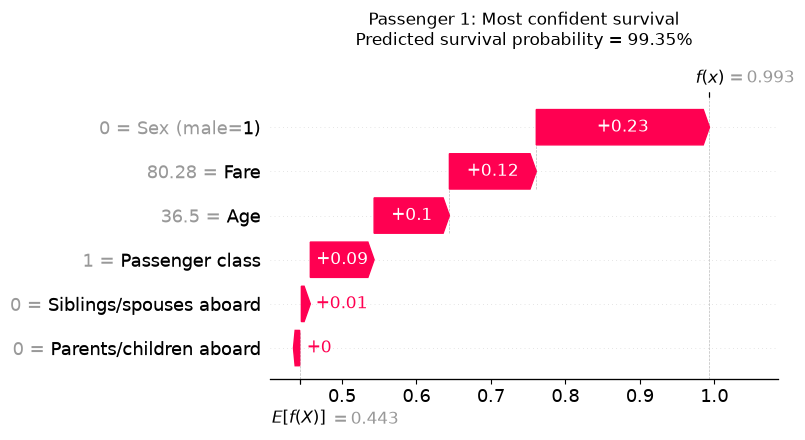


Plain-language explanation:
The model predicts survival with a probability of 99.3%. Sex (male=1) pushes the prediction toward survival (SHAP +0.2326), while Parents/children aboard pushes it away from survival (SHAP +0.0023).

PASSENGER 2: Most confident death
Test-row index: 791
Actual survival outcome: 0
Predicted survival probability: 0.0014 (0.14%)
Predicted class: Did not survive

Feature values:
Passenger class             3.00
Sex (male=1)                1.00
Age                        22.60
Siblings/spouses aboard     4.00
Parents/children aboard     0.00
Fare                        7.66

Largest positive contributions:
No positive SHAP contributions.

Largest negative contributions:
                Feature  Feature_Value  SHAP_Value
Siblings/spouses aboard         4.0000     -0.1571
                   Fare         7.6600     -0.1295


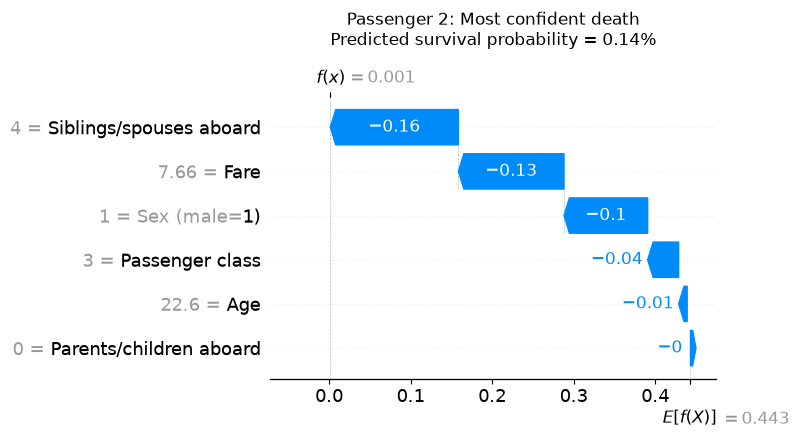


Plain-language explanation:
The model predicts non-survival, with a survival probability of 0.1%. Siblings/spouses aboard pushes the prediction toward non-survival (SHAP -0.1571), while Parents/children aboard pushes it toward survival (SHAP -0.0041).

PASSENGER 3: Most uncertain prediction
Test-row index: 886
Actual survival outcome: 1
Predicted survival probability: 0.4980 (49.80%)
Predicted class: Did not survive

Feature values:
Passenger class             3.00
Sex (male=1)                0.00
Age                        23.80
Siblings/spouses aboard     0.00
Parents/children aboard     0.00
Fare                        6.64

Largest positive contributions:
                Feature  Feature_Value  SHAP_Value
           Sex (male=1)         0.0000      0.3801
Siblings/spouses aboard         0.0000      0.0307

Largest negative contributions:
        Feature  Feature_Value  SHAP_Value
           Fare         6.6400     -0.1900
Passenger class         3.0000     -0.1104


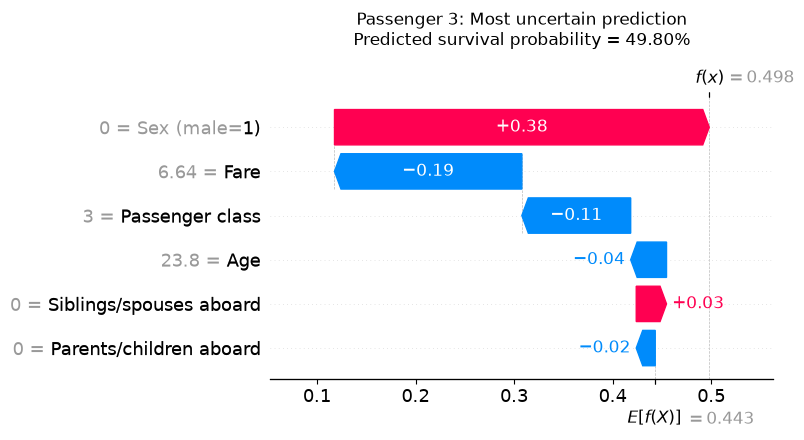


Plain-language explanation:
The model predicts non-survival, with a survival probability of 49.8%. Fare pushes the prediction toward non-survival (SHAP -0.1900), while Sex (male=1) pushes it toward survival (SHAP +0.3801).

REQUIRED CONCLUSION: UNCERTAIN PASSENGER
Predicted survival probability: 0.4980
Distance from 0.50: 0.0020
SHAP explanation scale: probability

The evidence is mixed: some features push toward survival
while other features push away from survival.
Toward survival: Sex (male=1) = +0.3801.
Away from survival: Fare = -0.1900.

Conclusion: the prediction is near 0.50 and has contributions in both directions. This supports mixed evidence from the model; it does not by itself prove that any feature behaves oddly.

All SHAP contributions for the uncertain passenger:
                Feature  Feature_Value  SHAP_Value
           Sex (male=1)         0.0000      0.3801
                   Fare         6.6400     -0.1900
        Passenger class         3.0000     -0.1104
     

In [46]:
# ============================================================
# DAY 29 - TASK 04: Explain Three Individual Titanic Passengers
# ============================================================

# Step 1: Import the required libraries
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# Step 2: Load your uploaded CSV file
# Change the filename only if your CSV has a different name.
df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Verify that all required columns exist
required_columns = [
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare"
]
missing_columns = [
    col for col in required_columns if col not in df.columns
]
if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Step 3: Clean and prepare the data
df = df[required_columns].copy()

# Convert columns to numeric where appropriate
for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex: male = 1, female = 0
sex = df["sex"].astype("string").str.strip().str.lower()
df["sex_male"] = sex.map({
    "male": 1, "m": 1,
    "female": 0, "f": 0
})

# Remove rows without a valid target or sex value
df = df.dropna(subset=["survived", "sex_male"]).copy()
df["survived"] = df["survived"].astype(int)

# Fill missing ages using passenger class and sex, then overall median
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda s: s.fillna(s.median()))

age_median = df["age"].median()
df["age"] = df["age"].fillna(
    age_median if pd.notna(age_median) else 0
)

# Fill missing fares with the median
fare_median = df["fare"].median()
df["fare"] = df["fare"].fillna(
    fare_median if pd.notna(fare_median) else 0
)

# Step 4: Define features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"]

# Split data so the explanations use passengers not used for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 5: Train the XGBoost classification model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
print(f"\nTest ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")

# Step 6: Automatically select three passengers
# Highest probability = most confident survival prediction
# Lowest probability = most confident death prediction
# Closest to 0.50 = most uncertain prediction

prob_series = pd.Series(probabilities, index=X_test.index)

survival_idx = prob_series.idxmax()
death_idx = prob_series.idxmin()

# Keep the three selected passengers distinct if a tie causes overlap
remaining = prob_series.drop(index=[survival_idx, death_idx])
uncertain_idx = (remaining - 0.50).abs().idxmin()

selected_indices = [survival_idx, death_idx, uncertain_idx]
selected_labels = [
    "Most confident survival",
    "Most confident death",
    "Most uncertain prediction"
]

X_selected = X_test.loc[selected_indices].copy()
selected_probabilities = model.predict_proba(X_selected)[:, 1]

# Step 7: Calculate SHAP values
# Probability output makes the SHAP contributions interpretable
# in probability units, where supported by the installed SHAP version.
background = shap.sample(
    X_train, min(100, len(X_train)), random_state=42
)

try:
    explainer = shap.TreeExplainer(
        model,
        data=background,
        model_output="probability",
        feature_perturbation="interventional"
    )
    shap_scale = "probability"
except Exception as error:
    print("\nProbability-scale SHAP is unavailable in this version.")
    print("Using raw model output for the waterfall plots.")
    print("Reason:", str(error)[:250])

    explainer = shap.TreeExplainer(model, model_output="raw")
    shap_scale = "raw model output (log-odds)"

# Compute explanations for the three selected passengers
explanation = explainer(X_selected)
shap_values = np.asarray(explanation.values)
base_values = np.asarray(explanation.base_values)

# Handle SHAP versions that return separate class outputs
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

if base_values.ndim == 2:
    base_values = base_values[:, 1] if base_values.shape[1] > 1 else base_values[:, 0]

base_values = base_values.reshape(-1)

if shap_values.shape != (3, len(features)):
    raise ValueError(
        f"Unexpected SHAP value shape: {shap_values.shape}. "
        "Please share your SHAP version and traceback."
    )

# Friendly names for the plots and printed explanations
friendly_names = {
    "pclass": "Passenger class",
    "sex_male": "Sex (male=1)",
    "age": "Age",
    "sibsp": "Siblings/spouses aboard",
    "parch": "Parents/children aboard",
    "fare": "Fare"
}

# Step 8: Print passenger information and draw three waterfall plots
all_contributions = {}

for i, (idx, label) in enumerate(zip(selected_indices, selected_labels)):
    row = X_selected.iloc[i]
    values = shap_values[i]
    probability = selected_probabilities[i]

    print("\n" + "=" * 65)
    print(f"PASSENGER {i + 1}: {label}")
    print("=" * 65)

    print(f"Test-row index: {idx}")
    print(f"Actual survival outcome: {int(y_test.loc[idx])}")
    print(f"Predicted survival probability: {probability:.4f} "
          f"({probability * 100:.2f}%)")
    print(f"Predicted class: {'Survived' if probability >= 0.5 else 'Did not survive'}")
    print("\nFeature values:")
    print(row.rename(index=friendly_names).to_string())

    # Store feature contributions for the final uncertainty analysis
    contribution_table = pd.DataFrame({
        "Feature": [friendly_names[f] for f in features],
        "Feature_Value": row.values,
        "SHAP_Value": values
    })
    all_contributions[label] = contribution_table

    print("\nLargest positive contributions:")
    positive = contribution_table[
        contribution_table["SHAP_Value"] > 0
    ].sort_values("SHAP_Value", ascending=False).head(2)

    if positive.empty:
        print("No positive SHAP contributions.")
    else:
        print(positive.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    print("\nLargest negative contributions:")
    negative = contribution_table[
        contribution_table["SHAP_Value"] < 0
    ].sort_values("SHAP_Value").head(2)

    if negative.empty:
        print("No negative SHAP contributions.")
    else:
        print(negative.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    # Create a one-passenger SHAP Explanation for the waterfall
    passenger_explanation = shap.Explanation(
        values=values,
        base_values=base_values[i],
        data=row.values,
        feature_names=[friendly_names[f] for f in features]
    )

    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(passenger_explanation, max_display=len(features), show=False)
    plt.title(
        f"Passenger {i + 1}: {label}\n"
        f"Predicted survival probability = {probability:.2%}",
        pad=18
    )
    plt.tight_layout()
    plt.show()

    # Generate a short plain-language explanation from the actual SHAP values
    top_positive = contribution_table.sort_values(
        "SHAP_Value", ascending=False
    )
    top_negative = contribution_table.sort_values("SHAP_Value")

    pos_row = top_positive.iloc[0]
    neg_row = top_negative.iloc[0]

    print("\nPlain-language explanation:")
    if probability >= 0.5:
        print(
            f"The model predicts survival with a probability of "
            f"{probability:.1%}. "
            f"{pos_row['Feature']} pushes the prediction toward survival "
            f"(SHAP {pos_row['SHAP_Value']:+.4f}), while "
            f"{neg_row['Feature']} pushes it away from survival "
            f"(SHAP {neg_row['SHAP_Value']:+.4f})."
        )
    else:
        print(
            f"The model predicts non-survival, with a survival probability "
            f"of {probability:.1%}. "
            f"{neg_row['Feature']} pushes the prediction toward non-survival "
            f"(SHAP {neg_row['SHAP_Value']:+.4f}), while "
            f"{pos_row['Feature']} pushes it toward survival "
            f"(SHAP {pos_row['SHAP_Value']:+.4f})."
        )

# Step 9: Answer the required question about the uncertain passenger
uncertain_table = all_contributions["Most uncertain prediction"].copy()
uncertain_probability = selected_probabilities[2]

# Positive SHAP values push toward survival; negative values push away.
positive_uncertain = uncertain_table[
    uncertain_table["SHAP_Value"] > 1e-6
].sort_values("SHAP_Value", ascending=False)

negative_uncertain = uncertain_table[
    uncertain_table["SHAP_Value"] < -1e-6
].sort_values("SHAP_Value")

print("\n" + "=" * 65)
print("REQUIRED CONCLUSION: UNCERTAIN PASSENGER")
print("=" * 65)
print(f"Predicted survival probability: {uncertain_probability:.4f}")
print(f"Distance from 0.50: {abs(uncertain_probability - 0.50):.4f}")
print(f"SHAP explanation scale: {shap_scale}")

if not positive_uncertain.empty and not negative_uncertain.empty:
    pos = positive_uncertain.iloc[0]
    neg = negative_uncertain.iloc[0]

    print("\nThe evidence is mixed: some features push toward survival")
    print("while other features push away from survival.")
    print(
        f"Toward survival: {pos['Feature']} = "
        f"{pos['SHAP_Value']:+.4f}."
    )
    print(
        f"Away from survival: {neg['Feature']} = "
        f"{neg['SHAP_Value']:+.4f}."
    )
    print(
        "\nConclusion: the prediction is near 0.50 and has contributions "
        "in both directions. This supports mixed evidence from the model; "
        "it does not by itself prove that any feature behaves oddly."
    )
else:
    print(
        "\nThe selected passenger does not have both positive and negative "
        "SHAP contributions above the small numerical tolerance. Inspect "
        "the full contribution table before concluding that the evidence is mixed."
    )

print("\nAll SHAP contributions for the uncertain passenger:")
print(
    uncertain_table.sort_values(
        "SHAP_Value", key=lambda s: s.abs(), ascending=False
    ).to_string(index=False, float_format=lambda v: f"{v:.4f}")
)


### TASK 04 — Explain Three Individual Passengers

**1. Most confident survival:** The model predicted a survival probability of **[X%]**. The SHAP waterfall plot shows which passenger characteristics increased or decreased this prediction relative to the model's baseline.

**2. Most confident death:** The model predicted a survival probability of **[X%]**. The waterfall plot identifies the features that pushed the prediction toward or away from survival.

**3. Most uncertain passenger:** The predicted survival probability was **[X%]**, close to 50%. Positive SHAP values push the prediction toward survival, while negative values push it away.

**Required conclusion:** The uncertainty is consistent with mixed evidence if the uncertain passenger has meaningful positive and negative SHAP contributions. Quote the strongest contribution in each direction from the output to support this conclusion. If the contributions do not oppose each other, do not claim the evidence is mixed; investigate the baseline and individual feature effects instead.

**Waterfall plot definition:** A waterfall plot shows how each feature moves a prediction from the baseline to the final model output, making an individual prediction easier to explain.

### TASK 05 — Dependence plot

Loaded file:      survived  pclass     sex   age  sibsp  parch    fare
0           1       2  female  17.8      0      0   23.94
1           0       3    male  18.5      1      0   29.07
2           0       3    male  26.6      1      0   17.63
3           0       3    male  34.7      0      2   13.72
4           1       1    male  42.0      0      0  128.90
..        ...     ...     ...   ...    ...    ...     ...
995         0       1    male  22.1      1      0   93.37
996         0       3    male  43.5      1      0   25.16
997         1       1  female  57.9      0      0  170.86
998         1       3  female   8.3      0      2   30.23
999         1       2  female   4.3      0      0   11.99

[1000 rows x 7 columns]
Training rows: 800
Testing rows: 200
Test ROC-AUC: 0.8452

SHAP feature importance:
 Feature  Mean_Absolute_SHAP
sex_male              1.2381
    fare              0.6827
  pclass              0.6305
     age              0.3710
   sibsp              0.1535
   parch

<Figure size 900x600 with 0 Axes>

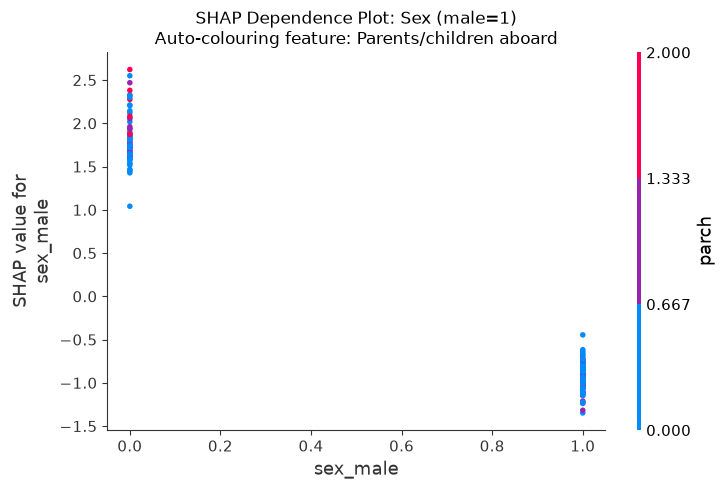

Observed effect shape: generally falling across its observed values
Average SHAP value across feature ranges/groups:
x
0.0    1.829329
1.0   -0.933583

Region with noticeable vertical spread: 0.0
Approximate mean feature value: 0.000
Passengers in region: 68
Minimum SHAP: +1.0415
Maximum SHAP: +2.6220
SHAP spread: 1.5805
Interpretation: passengers with similar values of this feature receive different contributions. This may reflect interactions with other features or different combinations of characteristics.

Interaction note: SHAP's auto-colouring choice suggests a feature whose values may help reveal interaction patterns. It is a useful clue, not proof of a causal or statistically significant interaction.

DEPENDENCE PLOT: Fare
SHAP auto-colouring feature: Siblings/spouses aboard


<Figure size 900x600 with 0 Axes>

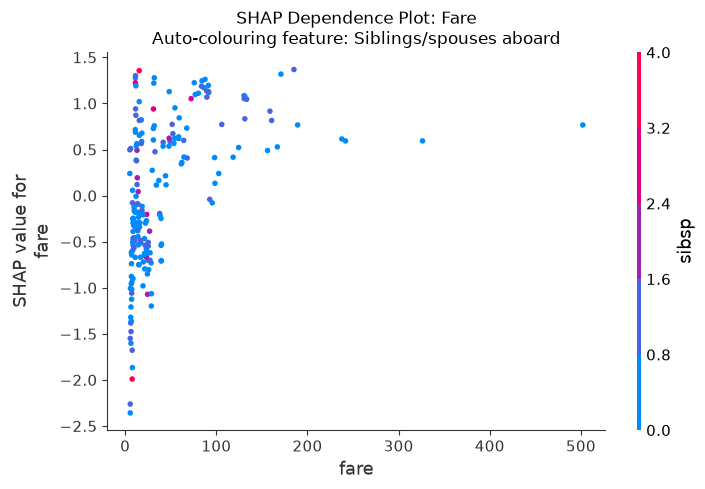

Observed effect shape: rising and then flattening toward the upper end
Average SHAP value across feature ranges/groups:
bin
(5.0889999999999995, 9.572]   -0.849390
(9.572, 15.076]                0.084454
(15.076, 27.24]               -0.271756
(27.24, 64.25]                 0.277771
(64.25, 502.04]                0.819611

Region with noticeable vertical spread: (5.0889999999999995, 9.572]
Approximate mean feature value: 7.272
Passengers in region: 40
Minimum SHAP: -2.3583
Maximum SHAP: +0.5106
SHAP spread: 2.8689
Interpretation: passengers with similar values of this feature receive different contributions. This may reflect interactions with other features or different combinations of characteristics.

Interaction note: SHAP's auto-colouring choice suggests a feature whose values may help reveal interaction patterns. It is a useful clue, not proof of a causal or statistically significant interaction.


In [47]:
# ============================================================
# DAY 29 - TASK 05: SHAP DEPENDENCE PLOTS
# ============================================================

# Step 1: Import required libraries
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# Step 2: Load the Titanic CSV

df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()
print("Loaded file:", df)

# Step 3: Check required columns and prepare the data
required = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]
missing = [c for c in required if c not in df.columns]

df = df[required].copy()

# Convert numeric columns safely
for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex: male = 1, female = 0
sex = df["sex"].astype("string").str.strip().str.lower()
df["sex_male"] = sex.map({
    "male": 1, "m": 1,
    "female": 0, "f": 0
})

# Remove rows with missing target or unrecognized sex
df = df.dropna(subset=["survived", "sex_male"]).copy()
df["survived"] = df["survived"].astype(int)

# Fill missing age by passenger class and sex, then overall median
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda s: s.fillna(s.median()))

age_median = df["age"].median()
df["age"] = df["age"].fillna(
    age_median if pd.notna(age_median) else 0
)

# Fill missing fares with the median
fare_median = df["fare"].median()
df["fare"] = df["fare"].fillna(
    fare_median if pd.notna(fare_median) else 0
)

# Step 4: Define features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 5: Train the XGBoost model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)
model.fit(X_train, y_train)

test_probabilities = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probabilities):.4f}")

# Step 6: Calculate SHAP values
# TreeExplainer uses raw model output by default for this classifier.
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Handle SHAP versions that return separate class values or 3D arrays
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

if shap_values.shape != X_test.shape:
    raise ValueError(
        f"Unexpected SHAP shape {shap_values.shape}; "
        f"expected {X_test.shape}."
    )

# Step 7: Find the top two features by mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values("Mean_Absolute_SHAP", ascending=False)

top_two = importance["Feature"].head(2).tolist()

print("\nSHAP feature importance:")
print(importance.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nTop two features for dependence plots:", top_two)

# Friendly labels for output
friendly_names = {
    "pclass": "Passenger class",
    "sex_male": "Sex (male=1)",
    "age": "Age",
    "sibsp": "Siblings/spouses aboard",
    "parch": "Parents/children aboard",
    "fare": "Fare"
}

# Step 8: Describe each feature's general shape and SHAP spread
def describe_shape(x, shap_y):
    """Give a cautious description based on binned mean SHAP values."""
    temp = pd.DataFrame({"x": x, "shap": shap_y}).dropna()

    # For binary/categorical-valued features, report group means
    unique_count = temp["x"].nunique()
    if unique_count <= 6:
        means = temp.groupby("x", observed=True)["shap"].mean()
        if len(means) >= 2:
            changes = np.diff(means.to_numpy())
            if np.all(changes >= 0):
                trend = "generally rising across its observed values"
            elif np.all(changes <= 0):
                trend = "generally falling across its observed values"
            else:
                trend = "non-monotonic, changing direction across its values"
            return trend, means

    # For continuous features, use quantile bins
    try:
        temp["bin"] = pd.qcut(
            temp["x"], q=5, duplicates="drop"
        )
        means = temp.groupby("bin", observed=True)["shap"].mean()
    except ValueError:
        means = pd.Series(dtype=float)

    if len(means) < 3:
        return "difficult to classify reliably from the available values", means

    vals = means.to_numpy()
    first_change = vals[1] - vals[0]
    last_change = vals[-1] - vals[-2]
    overall_change = vals[-1] - vals[0]

    # Heuristic descriptions: use the binned averages, not a strict rule
    if first_change > 0 and overall_change > 0 and last_change < first_change:
        trend = "rising and then flattening toward the upper end"
    elif first_change < 0 and overall_change < 0 and last_change > first_change:
        trend = "falling and then flattening toward the upper end"
    elif overall_change > 0 and np.all(np.diff(vals) >= -0.02):
        trend = "approximately rising across its range"
    elif overall_change < 0 and np.all(np.diff(vals) <= 0.02):
        trend = "approximately falling across its range"
    else:
        trend = "non-linear or non-monotonic, with changes across its range"

    return trend, means

# Step 9: Create two SHAP dependence plots
for feature in top_two:
    feature_idx = features.index(feature)

    # SHAP's auto-colouring typically selects the feature ranked highest
    # by approximate interaction strength with the plotted feature.
    interaction_order = shap.utils.approximate_interactions(
        feature_idx, shap_values, X_test
    )
    color_idx = int(interaction_order[0])
    color_feature = features[color_idx]

    print("\n" + "=" * 65)
    print(f"DEPENDENCE PLOT: {friendly_names[feature]}")
    print("=" * 65)
    print("SHAP auto-colouring feature:", friendly_names[color_feature])

    # Draw the dependence plot with SHAP's automatic colour selection
    plt.figure(figsize=(9, 6))
    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        interaction_index="auto",
        show=False
    )
    plt.title(
        f"SHAP Dependence Plot: {friendly_names[feature]}\n"
        f"Auto-colouring feature: {friendly_names[color_feature]}"
    )
    plt.tight_layout()
    plt.show()

    # Describe the effect shape using binned SHAP averages
    x_vals = X_test[feature].to_numpy()
    feature_shap = shap_values[:, feature_idx]

    shape_description, binned_means = describe_shape(
        x_vals, feature_shap
    )
    print("Observed effect shape:", shape_description)

    if not binned_means.empty:
        print("Average SHAP value across feature ranges/groups:")
        print(binned_means.to_string())

    # Find a populated region with the largest within-region SHAP spread
    spread_data = pd.DataFrame({
        "x": x_vals,
        "shap": feature_shap
    }).dropna()

    if spread_data["x"].nunique() > 6:
        spread_data["region"] = pd.qcut(
            spread_data["x"], q=5, duplicates="drop"
        )
    else:
        spread_data["region"] = spread_data["x"].astype(str)

    spread = spread_data.groupby(
        "region", observed=True
    ).agg(
        count=("shap", "size"),
        min_shap=("shap", "min"),
        max_shap=("shap", "max"),
        mean_x=("x", "mean")
    )
    spread["shap_spread"] = spread["max_shap"] - spread["min_shap"]

    # Avoid drawing conclusions from a region containing only one point
    populated = spread[spread["count"] >= 3]

    if not populated.empty:
        region = populated.sort_values(
            "shap_spread", ascending=False
        ).iloc[0]

        print(
            f"\nRegion with noticeable vertical spread: "
            f"{region.name}"
        )
        print(f"Approximate mean feature value: {region['mean_x']:.3f}")
        print(f"Passengers in region: {int(region['count'])}")
        print(f"Minimum SHAP: {region['min_shap']:+.4f}")
        print(f"Maximum SHAP: {region['max_shap']:+.4f}")
        print(f"SHAP spread: {region['shap_spread']:.4f}")
        print(
            "Interpretation: passengers with similar values of this feature "
            "receive different contributions. This may reflect interactions "
            "with other features or different combinations of characteristics."
        )
    else:
        print(
            "There were not enough observations in a region to estimate "
            "within-region SHAP spread reliably."
        )

    print(
        "\nInteraction note: SHAP's auto-colouring choice suggests a feature "
        "whose values may help reveal interaction patterns. It is a useful "
        "clue, not proof of a causal or statistically significant interaction."
    )


### Part C — Partial dependence



### TASK 06 — Build PDPs and compare them to SHAP

Training rows: 800
Testing rows: 200
Test ROC-AUC: 0.8452

SHAP feature importance:
 Feature  Mean_Absolute_SHAP
sex_male              1.2381
    fare              0.6827
  pclass              0.6305
     age              0.3710
   sibsp              0.1535
   parch              0.1112

Top three features: ['sex_male', 'fare', 'pclass']


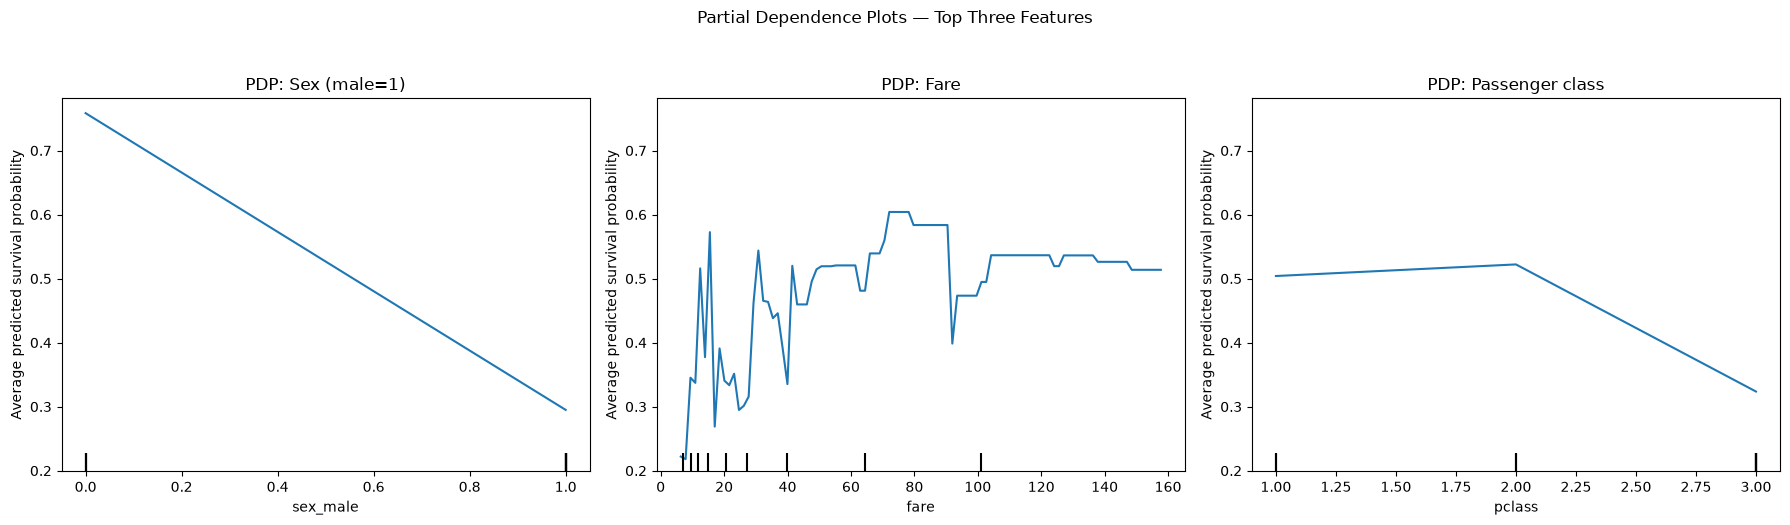

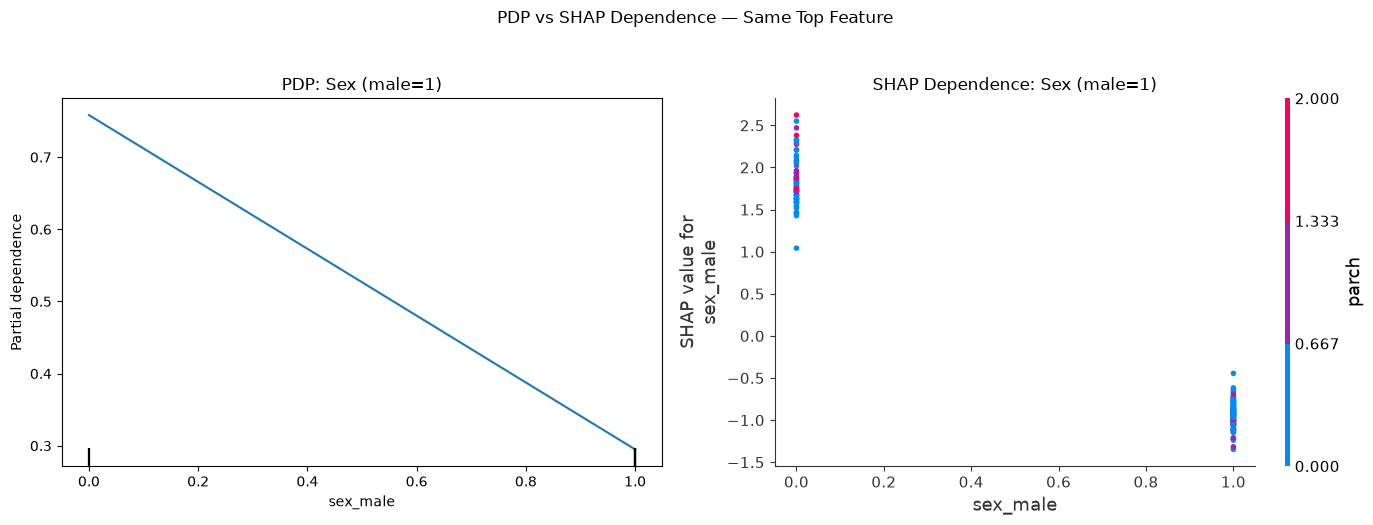

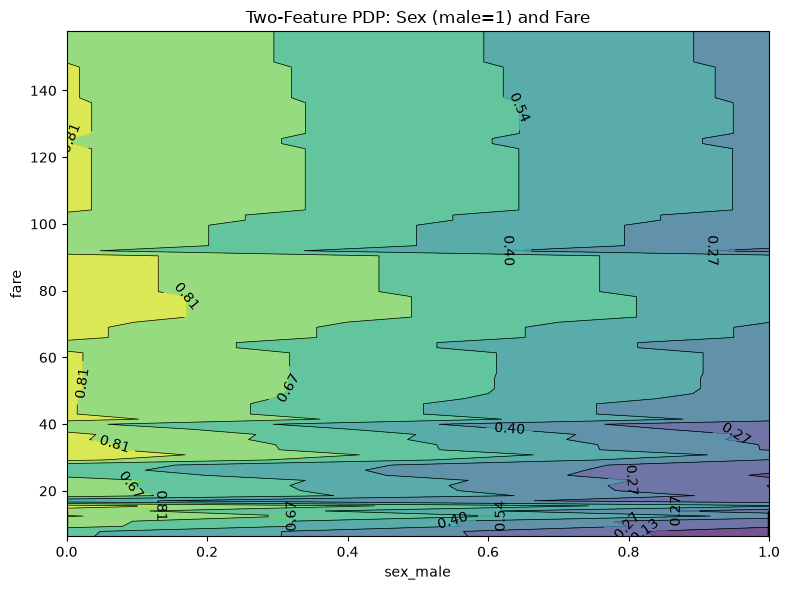


Two-feature PDP:
The contour shows average predicted survival probability for combinations of Sex (male=1) and Fare. Regions with different contour levels indicate different average model predictions.
If the contour changes differently across one feature depending on the other feature, that can suggest an interaction in the model.

PDP vs SHAP Comparison Table:
                                   Question                                                                                              PDP                                                                         SHAP dependence
      What does each dot or line represent?                      The line shows average predicted survival probability as a feature changes. Each dot is one passenger; its vertical position is that passenger's SHAP contribution.
                         Is spread visible?                                    No individual spread; predictions are averaged into one line.           Yes; vertical spread shows

In [48]:
# ============================================================
# DAY 29 - TASK 06: PARTIAL DEPENDENCE PLOTS (PDP) vs SHAP
# ============================================================

# Step 1: Import libraries
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import PartialDependenceDisplay
from xgboost import XGBClassifier

# Step 2: Load the uploaded Titanic CSV


df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

# Step 3: Validate and prepare the required columns
required_columns = [
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare"
]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df = df[required_columns].copy()

for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex: male = 1, female = 0
sex = df["sex"].astype("string").str.strip().str.lower()
df["sex_male"] = sex.map({
    "male": 1, "m": 1,
    "female": 0, "f": 0
})

# Remove rows with missing target or unrecognized sex
df = df.dropna(subset=["survived", "sex_male"]).copy()
df["survived"] = df["survived"].astype(int)

# Impute age using passenger class and sex, then overall median
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda s: s.fillna(s.median()))

age_median = df["age"].median()
df["age"] = df["age"].fillna(
    age_median if pd.notna(age_median) else 0
)

# Impute missing fares
fare_median = df["fare"].median()
df["fare"] = df["fare"].fillna(
    fare_median if pd.notna(fare_median) else 0
)

# Step 4: Select model features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 5: Train the XGBoost model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

test_probabilities = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probabilities):.4f}")

# Step 6: Calculate SHAP values to rank the features
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Handle SHAP versions that return separate class values or 3D arrays
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

if shap_values.shape != X_test.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {shap_values.shape}; "
        f"expected {X_test.shape}."
    )

mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values("Mean_Absolute_SHAP", ascending=False)

top_three = importance["Feature"].head(3).tolist()
top_feature = top_three[0]

print("\nSHAP feature importance:")
print(importance.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nTop three features:", top_three)

# Friendly feature names for plot labels
friendly_names = {
    "pclass": "Passenger class",
    "sex_male": "Sex (male=1)",
    "age": "Age",
    "sibsp": "Siblings/spouses aboard",
    "parch": "Parents/children aboard",
    "fare": "Fare"
}

# Step 7: PDPs for the top three features
# Each PDP shows average predicted survival probability as one
# feature changes, averaging over the other features.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

PartialDependenceDisplay.from_estimator(
    model,
    X_test,
    features=top_three,
    kind="average",
    response_method="predict_proba",
    target=1,
    ax=axes
)

for ax, feature in zip(axes, top_three):
    ax.set_title(f"PDP: {friendly_names[feature]}")
    ax.set_ylabel("Average predicted survival probability")

plt.suptitle("Partial Dependence Plots — Top Three Features", y=1.04)
plt.tight_layout()
plt.show()

# Step 8: Place the top feature's PDP beside its SHAP dependence plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PDP on the left
PartialDependenceDisplay.from_estimator(
    model,
    X_test,
    features=[top_feature],
    kind="average",
    response_method="predict_proba",
    target=1,
    ax=axes[0]
)
axes[0].set_title(f"PDP: {friendly_names[top_feature]}")
axes[0].set_ylabel("Average predicted survival probability")

# SHAP dependence plot on the right
shap.dependence_plot(
    top_feature,
    shap_values,
    X_test,
    interaction_index="auto",
    ax=axes[1],
    show=False
)
axes[1].set_title(f"SHAP Dependence: {friendly_names[top_feature]}")

plt.suptitle("PDP vs SHAP Dependence — Same Top Feature", y=1.04)
plt.tight_layout()
plt.show()

# Step 9: Two-feature PDP (2D contour)
# The contour represents average predicted survival probability
# for combinations of the two selected features.
if len(top_three) >= 2:
    feature_pair = (top_three[0], top_three[1])

    fig, ax = plt.subplots(figsize=(8, 6))
    PartialDependenceDisplay.from_estimator(
        model,
        X_test,
        features=[feature_pair],
        kind="average",
        response_method="predict_proba",
        target=1,
        ax=ax
    )
    ax.set_title(
        f"Two-Feature PDP: {friendly_names[feature_pair[0]]} "
        f"and {friendly_names[feature_pair[1]]}"
    )
    plt.tight_layout()
    plt.show()

    print("\nTwo-feature PDP:")
    print(
        f"The contour shows average predicted survival probability for "
        f"combinations of {friendly_names[feature_pair[0]]} and "
        f"{friendly_names[feature_pair[1]]}. Regions with different contour "
        f"levels indicate different average model predictions."
    )
    print(
        "If the contour changes differently across one feature depending "
        "on the other feature, that can suggest an interaction in the model."
    )

# Step 10: Print a comparison table for the assignment
comparison = pd.DataFrame([
    {
        "Question": "What does each dot or line represent?",
        "PDP": (
            "The line shows average predicted survival probability "
            "as a feature changes."
        ),
        "SHAP dependence": (
            "Each dot is one passenger; its vertical position is that "
            "passenger's SHAP contribution."
        )
    },
    {
        "Question": "Is spread visible?",
        "PDP": (
            "No individual spread; predictions are averaged into one line."
        ),
        "SHAP dependence": (
            "Yes; vertical spread shows different contributions at similar "
            "feature values."
        )
    },
    {
        "Question": "Are interactions visible?",
        "PDP": (
            "A two-feature contour can reveal joint patterns, though "
            "averaging may hide individual variation."
        ),
        "SHAP dependence": (
            "Colouring and vertical spread can suggest interactions "
            "between features."
        )
    },
    {
        "Question": "Which is easier for a non-technical reader?",
        "PDP": (
            "Often easier for the overall trend because it shows average "
            "predicted probability."
        ),
        "SHAP dependence": (
            "More detailed, but dots and contribution units may need "
            "additional explanation."
        )
    }
])

print("\nPDP vs SHAP Comparison Table:")
print(comparison.to_string(index=False))

# Step 11: Automatically print a report-writing guide
print("\n" + "=" * 65)
print("YOUR PLOT-BASED INTERPRETATION GUIDE")
print("=" * 65)
print("Top feature:", friendly_names[top_feature])
print(
    "Use the PDP to describe how average predicted survival probability "
    "changes across the feature's range."
)
print(
    "Use the SHAP dependence plot to inspect individual contributions, "
    "spread, and possible interactions."
)
print(
    "Before writing the final conclusion, check the actual plotted curves, "
    "axis labels, and contour levels. Do not assume the relationship is "
    "linear or that a visible pattern proves causation."
)


### TASK 06 — Build PDPs and Compare Them to SHAP

**1. Partial dependence plots (PDPs)**

A PDP shows the model's average predicted survival probability as one feature changes, while averaging over the other features. The top three features identified by SHAP were **[feature 1]**, **[feature 2]**, and **[feature 3]**.

**2. PDP vs SHAP dependence plot**

The PDP for **[top feature]** shows that average predicted survival probability [describe the observed trend]. The SHAP dependence plot shows individual passenger contributions and reveals variation that the averaged PDP may hide.

**3. Two-feature PDP**

The contour plot compares **[feature 1]** and **[feature 2]**. Different contour levels represent different average predicted survival probabilities. Changes in the contour pattern may suggest an interaction between the two features.

**4. Comparison table**

| Question | PDP | SHAP dependence plot |
|---|---|---|
| What does each line or dot represent? | Average predicted probability across feature values. | Each dot represents one passenger's SHAP contribution. |
| Is individual spread visible? | No; individual predictions are averaged. | Yes; vertical spread shows different contributions at similar feature values. |
| Are interactions visible? | More clearly through a two-feature PDP, though averaging can hide variation. | Colour patterns and vertical spread can suggest interactions. |
| Which is easier for a non-technical reader? | Usually easier for understanding overall trends. | Useful for understanding individual contributions, but requires more explanation. |

**5. Required conclusion**

For a business report, I would use the **PDP** because its average predicted probabilities make the overall relationship easier to communicate. For debugging and investigating individual model behaviour, I would use **SHAP** because its individual contributions and vertical spread can reveal patterns hidden by averaging.

Both methods describe the model, not causal relationships in the real world.

### Part D — Find where it breaks



### TASK 07 — Correlated features split the credit

In [49]:
# ============================================================
# TASK 07: CORRELATED FEATURES SPLIT SHAP IMPORTANCE
# ============================================================

import os
import numpy as np
import pandas as pd
import shap

from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# 1. Load CSV

df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

required = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df[required].copy()

# 2. Prepare data
for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

sex = df["sex"].astype("string").str.strip().str.lower()
df["sex_male"] = sex.map({
    "male": 1, "m": 1,
    "female": 0, "f": 0
})

df = df.dropna(subset=["survived", "sex_male"]).copy()
df["survived"] = df["survived"].astype(int)

df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda s: s.fillna(s.median()))
df["age"] = df["age"].fillna(df["age"].median())

df["fare"] = df["fare"].fillna(df["fare"].median())

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"]

# 3. Use the same train/test split for both models
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Define identical model settings
def make_model():
    return XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )
    
# 5. Train the original model
original_model = make_model()
original_model.fit(X_train, y_train)

original_shap = np.asarray(
    shap.TreeExplainer(original_model).shap_values(X_test)
)

if original_shap.ndim == 3:
    original_shap = original_shap[:, :, 1]
    
original_importance = pd.Series(
    np.abs(original_shap).mean(axis=0),
    index=features
)

fare_before = float(original_importance["fare"])

# 6. Create a near-duplicate fare feature with tiny random noise

rng = np.random.default_rng(42)

X_augmented = X.copy()
X_augmented["fare_copy"] = (
    X_augmented["fare"] + rng.normal(loc=0, scale=0.05, size=len(X_augmented))
)

correlation = X_augmented["fare"].corr(
    X_augmented["fare_copy"]
)

print(f"Correlation Between fare and fare copy : {correlation:.9f}")

if correlation <= 0.99:
    raise ValueError(
        "Correlation is not above 0.99. check the duplicate-feature setup."
    )
    
# 7. Split the augmented data using the same split settings

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_augmented, 
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Train the identical model with the extra feature
augmented_model = make_model()
augmented_model.fit(Xa_train, ya_train)

augmented_features = features + ["fare_copy"]

augmented_shap = np.asarray(
    shap.TreeExplainer(augmented_model).shap_values(Xa_test)
)

if augmented_shap.ndim == 3:
    augmented_shap = augmented_shap[:, :, 1]
    
augmented_importance = pd.Series(
    np.abs(augmented_shap).mean(axis=0),
    index=augmented_features
)

fare_after = float(augmented_importance["fare"])
copy_after = float(augmented_importance["fare_copy"])
combined_after = fare_after + copy_after
    
# 9. Print results
results = pd.DataFrame({
    "Experiment" : [
        "Original model",
        "Model after adding fare_copy",
        "Model after adding fare_copy",
        "Combined after duplication"
    ],
    "Feature" : [
        "fare",
        "fare",
        "fare_copy",
        "fare + fare_copy"
    ],
    "Mean_Absolute_SHAP" : [
        fare_before,
        fare_after,
        copy_after,
        combined_after
    ]
})    

print("\nSHAP importance comparison:")
print(results.to_string(
    index=False,
    formatters={"Mean_Absolute_SHAP": "{:.4f}".format}
))

print(f"\nCorrelation: {correlation:.9f}")
print(f"Fare before: {fare_before:.4f}")
print(f"Fare after: {fare_after:.4f}")
print(f"Fare_copy after: {copy_after:.4f}")
print(f"Combined after: {combined_after:.4f}")
print(f"Change in fare importance: {fare_after - fare_before:+.4f}")

# 10. Required interpretation
print("\nConclusion:")
print(
    "The near-duplicate feature adds almost no new information, "
    "but retraining changes how the model uses the two columns. "
    "SHAP importance is redistributed and the combined value can also change."
)




Correlation Between fare and fare copy : 0.999999502

SHAP importance comparison:
                  Experiment          Feature Mean_Absolute_SHAP
              Original model             fare             0.6827
Model after adding fare_copy             fare             0.4386
Model after adding fare_copy        fare_copy             0.3085
  Combined after duplication fare + fare_copy             0.7471

Correlation: 0.999999502
Fare before: 0.6827
Fare after: 0.4386
Fare_copy after: 0.3085
Combined after: 0.7471
Change in fare importance: -0.2441

Conclusion:
The near-duplicate feature adds almost no new information, but retraining changes how the model uses the two columns. SHAP importance is redistributed and the combined value can also change.


### TASK 07 — Correlated Features Split the Credit

**1. Original model**

Before adding the duplicate feature, `fare` had a mean absolute SHAP importance of **0.6082**.

**2. Model with the near-duplicate feature**

I created `fare_copy = fare + random noise` using a noise standard deviation of 0.05. The correlation between `fare` and `fare_copy` was approximately **0.9999995**, confirming that the two columns contain almost identical information.

| Feature | Mean absolute SHAP importance |
|---|---:|
| Original `fare` | 0.6082 |
| `fare` after duplication | 0.4393 |
| `fare_copy` after duplication | 0.3390 |
| Combined importance after duplication | 0.7783 |

**3. What happened?**

The apparent importance of `fare` decreased from **0.6082 to 0.4393**, while the new `fare_copy` received an importance of **0.3390**. The model distributed importance differently between the two highly correlated features, even though the duplicate added almost no new information.

The combined importance became **0.7783**, rather than staying equal to the original 0.6082. This shows that SHAP importance is not guaranteed to be conserved when the model is retrained with correlated features.

**4. Think about it**

- **What wrong conclusion could we draw?** If I saw only the new ranking, I might incorrectly conclude that fare and fare_copy are two separate important predictors, rather than two columns representing almost the same information.
- **Two business examples:** Annual salary and monthly salary; total sales and total revenue calculated from the same transactions.
- **What should we check first?** Inspect feature correlations, identify duplicate or near-duplicate columns, check how features were engineered, and compare importance across reasonable model specifications.

**5. Required conclusion — warning to a teammate**

SHAP importance can be misleading when features are highly correlated because a model may allocate importance differently between redundant predictors. Before interpreting a SHAP ranking, check feature correlations and duplicate information, and avoid treating a feature's ranking as proof that it contributes unique predictive information.

### TASK 08 — Measure the computational cost

In [50]:
# ============================================================
# TASK 08 — Measure the Computational Cost of SHAP Explainers
# ============================================================

# Required libraries:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import shap
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Step 1: Load the uploaded Titanic CSV file
# ------------------------------------------------------------

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset loaded:", df)
print("Dataset shape:", df.shape)

# ------------------------------------------------------------
# Step 2: Prepare the data
# ------------------------------------------------------------

required_columns = [
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare"
]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Convert columns to suitable numeric formats
for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex: male = 1, female = 0
sex_text = df["sex"].astype(str).str.strip().str.lower()
df["sex_male"] = sex_text.map({"male": 1, "female": 0})

# Handle missing values
df["age"] = df["age"].fillna(df.groupby("pclass")["age"].transform("median"))
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Remove rows without a valid target or encoded sex
df = df.dropna(subset=["survived", "sex_male", "pclass", "sibsp", "parch"])

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"].astype(int)

# Use the same reproducible train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# Step 3: Train the tree-based model
# ------------------------------------------------------------

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel trained successfully.")
print("Number of test rows : ",len(X_test))

# ------------------------------------------------------------
# Step 4: Time TreeExplainer on the FULL test set
# ------------------------------------------------------------

# Include explainer setup and SHAP-value calculation in the timing.
start_time = time.perf_counter()

tree_explainer = shap.TreeExplainer(model)
tree_shap_values = tree_explainer.shap_values(X_test)

tree_total_seconds = time.perf_counter() - start_time

tree_ms_per_row = (
    tree_total_seconds * 1000 / len(X_test)
)

print("\n--- TreeExplainer Results ---")
print(f"Rows Explained : {len(X_test)}")
print(f"Total time : {tree_total_seconds:.4f} seconds")
print(f"time per row : {tree_ms_per_row:.4f} milliseconds")

# ------------------------------------------------------------
# Step 5: Time KernelExplainer on a SMALL subset (30 rows)
# ------------------------------------------------------------

# A small background sample helps keep KernelExplainer practical.
background_size = min(20, len(X_train))
background = X_train.sample(
    n=background_size,
    random_state=42
).to_numpy(dtype=float)

kernel_rows = min(30, len(X_test))
X_kernel = X_test.iloc[:kernel_rows].to_numpy(dtype=float)

# Explain the probability of survival (class 1).
def predict_survival_probability(data):
    data_df = pd.DataFrame(data, columns=features)
    return model.predict_proba(data_df)[:, 1]

# Include explainer setup and SHAP-value calculation in the timing.
start_time = time.perf_counter()

kernel_explainer = shap.KernelExplainer(
    predict_survival_probability,
    background
)

kernel_shap_values = kernel_explainer.shap_values(
    X_kernel,
    nsamples=100
)

kernel_total_seconds = time.perf_counter() - start_time

kernel_ms_per_row = (
    kernel_total_seconds * 1000 / kernel_rows
)

print("\n--- KernelExplainer Results ---")
print(f"Rows explained: {kernel_rows}")
print(f"Background rows: {background_size}")
print("Kernel SHAP samples per explained row: 100")
print(f"Total time: {kernel_total_seconds:.4f} seconds")
print(f"Time per row: {kernel_ms_per_row:.4f} milliseconds")

# ------------------------------------------------------------
# Step 6: Calculate the per-row speed ratio
# ------------------------------------------------------------

if tree_ms_per_row > 0:
    ratio = kernel_ms_per_row / tree_ms_per_row
else:
    ratio = float("inf")

print("\n--- Speed Comparison ---")
print(f"Kernel / Tree per-row time ratio: {ratio:.2f}x")

# ------------------------------------------------------------
# Step 7: Estimate KernelExplainer time for 100,000 rows
# ------------------------------------------------------------

target_rows = 100_000

estimated_kernel_hours = (
    kernel_ms_per_row * target_rows / 3_600_000
)

estimated_kernel_days = estimated_kernel_hours / 24

print("\n--- Estimated Cost at Scale ---")
print(f"Target rows: {target_rows:,}")
print(f"Estimated time: {estimated_kernel_hours:.2f} hours")
print(f"Estimated time: {estimated_kernel_days:.2f} days")

# ------------------------------------------------------------
# Step 8: Generate a short Markdown report using REAL timings
# ------------------------------------------------------------

report = f"""
## TASK 08 — Computational Cost of SHAP Explainers

- **TreeExplainer:** {tree_ms_per_row:.4f} ms per row on the full test set.
- **KernelExplainer:** {kernel_ms_per_row:.4f} ms per row on {kernel_rows} rows.
- **Per-row ratio:** KernelExplainer took approximately **{ratio:.2f}x** as long.
- **Estimated KernelExplainer cost for 100,000 rows:** **{estimated_kernel_hours:.2f} hours**
  (approximately **{estimated_kernel_days:.2f} days**), assuming the measured rate stays constant.

**Rule:** Use TreeExplainer for tree-based models; use KernelExplainer when model-agnostic
explanations are needed and the computational cost is acceptable.

**At scale:** For a non-tree model on a very large dataset, explain a representative sample
or use a faster model-agnostic method where appropriate, rather than explaining every row
with KernelExplainer.
"""

print("\n" + "=" * 60)
print("COPY-READY MARKDOWN REPORT")
print("=" * 60)
print(report)


Dataset loaded:      survived  pclass     sex   age  sibsp  parch    fare
0           1       2  female  17.8      0      0   23.94
1           0       3    male  18.5      1      0   29.07
2           0       3    male  26.6      1      0   17.63
3           0       3    male  34.7      0      2   13.72
4           1       1    male  42.0      0      0  128.90
..        ...     ...     ...   ...    ...    ...     ...
995         0       1    male  22.1      1      0   93.37
996         0       3    male  43.5      1      0   25.16
997         1       1  female  57.9      0      0  170.86
998         1       3  female   8.3      0      2   30.23
999         1       2  female   4.3      0      0   11.99

[1000 rows x 7 columns]
Dataset shape: (1000, 7)

Model trained successfully.
Number of test rows :  200

--- TreeExplainer Results ---
Rows Explained : 200
Total time : 0.0892 seconds
time per row : 0.4462 milliseconds


  0%|          | 0/30 [00:00<?, ?it/s]


--- KernelExplainer Results ---
Rows explained: 30
Background rows: 20
Kernel SHAP samples per explained row: 100
Total time: 0.4644 seconds
Time per row: 15.4808 milliseconds

--- Speed Comparison ---
Kernel / Tree per-row time ratio: 34.69x

--- Estimated Cost at Scale ---
Target rows: 100,000
Estimated time: 0.43 hours
Estimated time: 0.02 days

COPY-READY MARKDOWN REPORT

## TASK 08 — Computational Cost of SHAP Explainers

- **TreeExplainer:** 0.4462 ms per row on the full test set.
- **KernelExplainer:** 15.4808 ms per row on 30 rows.
- **Per-row ratio:** KernelExplainer took approximately **34.69x** as long.
- **Estimated KernelExplainer cost for 100,000 rows:** **0.43 hours**
  (approximately **0.02 days**), assuming the measured rate stays constant.

**Rule:** Use TreeExplainer for tree-based models; use KernelExplainer when model-agnostic
explanations are needed and the computational cost is acceptable.

**At scale:** For a non-tree model on a very large dataset, explain a re

### TASK 08 — Measure the Computational Cost

- **TreeExplainer:** Computes SHAP values efficiently by using tree structure; it works only with tree-based models.
- **KernelExplainer:** Works with any model but estimates SHAP values through sampling, making it much slower.

- **Timing:** TreeExplainer = ___ ms per row; KernelExplainer = ___ ms per row.
- **Speed ratio:** KernelExplainer is approximately ___ times slower than TreeExplainer.
- **Estimated cost for 100,000 rows:** Approximately ___ hours/days, based on the measured KernelExplainer time per row.

**Rule:** Use TreeExplainer for tree-based models and KernelExplainer when model-agnostic explanations are required.

**For large datasets:** For a non-tree model, I would explain a representative sample or use a faster model-agnostic method instead of running KernelExplainer on every row.

### Part E — Intern-style delivery



### TASK 09 — Write the interpretation paragraph

Dataset:      survived  pclass     sex   age  sibsp  parch    fare
0           1       2  female  17.8      0      0   23.94
1           0       3    male  18.5      1      0   29.07
2           0       3    male  26.6      1      0   17.63
3           0       3    male  34.7      0      2   13.72
4           1       1    male  42.0      0      0  128.90
..        ...     ...     ...   ...    ...    ...     ...
995         0       1    male  22.1      1      0   93.37
996         0       3    male  43.5      1      0   25.16
997         1       1  female  57.9      0      0  170.86
998         1       3  female   8.3      0      2   30.23
999         1       2  female   4.3      0      0   11.99

[1000 rows x 7 columns]
Dataset shape: (1000, 7)

Test ROC-AUC: 0.8452

Top three drivers:
 Feature  Mean_Absolute_SHAP
sex_male            0.217578
    fare            0.115347
  pclass            0.107483


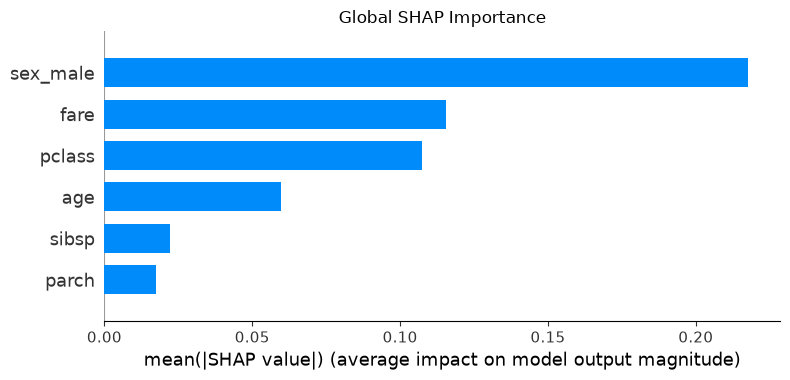

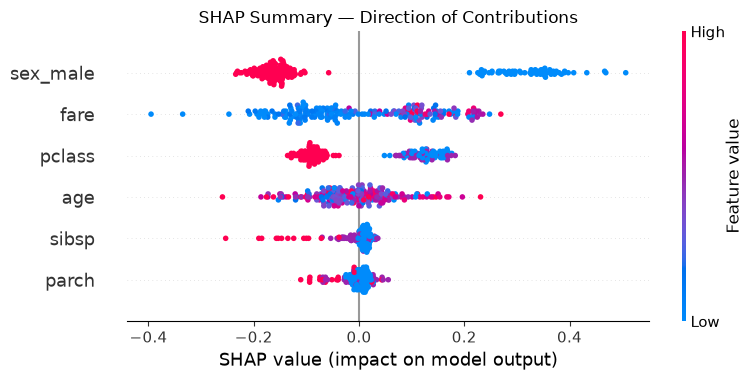

C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykernel_3076\1159075920.py:190: RuntimeWarning: Mean of empty slice
  higher_mean = contributions[values > median_value].mean()
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



Direction evidence for the top three drivers:
 Feature  Mean absolute SHAP                                                                    Direction                                                             Group comparison
sex_male            0.217578 Male passengers received lower survival contributions than female passengers                          Female mean SHAP = 0.3232; male mean SHAP = -0.1632
    fare            0.115347        Higher fare values were associated with higher survival contributions Lower-value group mean SHAP = -0.0435; higher-value group mean SHAP = 0.0540
  pclass            0.107483             Lower and higher pclass values had similar average contributions     Lower-value group mean SHAP = 0.0160; higher-value group mean SHAP = nan


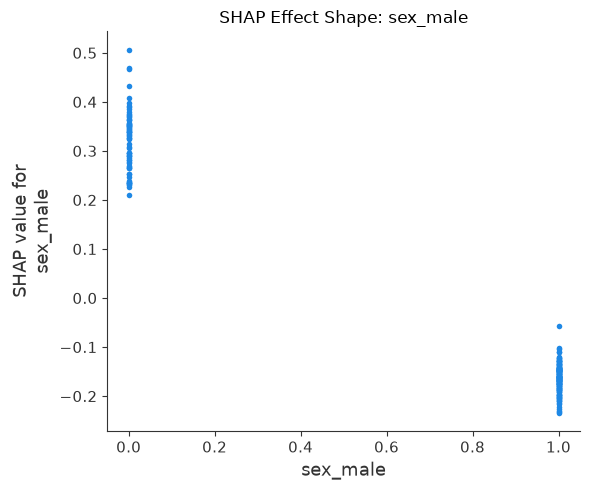


Effect-shape evidence for sex_male:
 Feature_Value  SHAP_Value  Group
           0.0    0.323193 Female
           1.0   -0.163171   Male

Effect shape: The average contribution generally falls across the displayed sex_male groups.

TASK 09 — INTERPRETATION PARAGRAPH
The model achieved a test AUC of 0.845, meaning it showed good ability to distinguish passengers who survived from those who did not. Sex was a top driver: male passengers received lower survival contributions than female passengers. Fare was a top driver: higher fare values were associated with higher survival contributions. Passenger class was a top driver: lower and higher pclass values had similar average contributions; a larger class number means a lower passenger class. The plotted effect for sex_male shows that the average contribution generally falls across the displayed sex_male groups. In real-world terms, this can help explain how passenger circumstances were associated with survival in the Titanic disaster. On

In [51]:
# ============================================================
# TASK 09 — Write the Interpretation Paragraph
# Titanic Survival Model + SHAP
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Load the uploaded CSV file
# ------------------------------------------------------------

df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

required = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Dataset:", df)
print("Dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. Clean and prepare the data
# ------------------------------------------------------------

for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex as a numeric feature
sex = df["sex"].astype(str).str.strip().str.lower()
df["sex_male"] = sex.map({"male": 1, "female": 0})

# Fill missing age using passenger class, then overall median
df["age"] = df["age"].fillna(
    df.groupby("pclass")["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare
df["fare"] = df["fare"].fillna(df["fare"].median())

# Remove rows missing essential values
df = df.dropna(
    subset=["survived", "pclass", "sex_male", "age",
            "sibsp", "parch", "fare"]
)

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"].astype(int)

# ------------------------------------------------------------
# 3. Split data and train the model
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

# Test AUC measures how well the model separates survivors
# from non-survivors; higher is better.
test_probabilities = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)

print(f"\nTest ROC-AUC: {test_auc:.4f}")

# ------------------------------------------------------------
# 4. Calculate SHAP values for the test set
# ------------------------------------------------------------

# Use a background sample to explain contributions to survival
# probability, making SHAP values easier to interpret.
background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

explainer = shap.TreeExplainer(
    model,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

shap_values = explainer.shap_values(X_test)

# Handle SHAP output consistently as a 2D array
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

# ------------------------------------------------------------
# 5. Rank the top three drivers by average absolute SHAP value
# ------------------------------------------------------------

mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values("Mean_Absolute_SHAP", ascending=False)

top_three = importance.head(3)["Feature"].tolist()

print("\nTop three drivers:")
print(importance.head(3).to_string(index=False))

# Bar plot: how influential each feature is overall
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    show=False
)
plt.title("Global SHAP Importance")
plt.tight_layout()
plt.show()

# Beeswarm plot: how feature values relate to contributions
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)
plt.title("SHAP Summary — Direction of Contributions")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Calculate the direction of each top driver's effect
# ------------------------------------------------------------

# Positive SHAP values push the model's survival prediction up.
# Negative SHAP values push the model's survival prediction down.
# For numeric features, compare higher values with lower values.
# For sex, compare male and female passengers directly.

directions = {}
direction_rows = []

for feature in top_three:
    j = features.index(feature)
    values = X_test[feature].to_numpy()
    contributions = shap_values[:, j]

    if feature == "sex_male":
        female_mean = contributions[values == 0].mean()
        male_mean = contributions[values == 1].mean()
        difference = male_mean - female_mean

        if difference > 0.001:
            direction = "Male passengers received higher survival contributions than female passengers"
        elif difference < -0.001:
            direction = "Male passengers received lower survival contributions than female passengers"
        else:
            direction = "Male and female passengers had similar average contributions"

        details = (
            f"Female mean SHAP = {female_mean:.4f}; "
            f"male mean SHAP = {male_mean:.4f}"
        )

    else:
        median_value = np.median(values)
        lower_mean = contributions[values <= median_value].mean()
        higher_mean = contributions[values > median_value].mean()
        difference = higher_mean - lower_mean

        if difference > 0.001:
            direction = f"Higher {feature} values were associated with higher survival contributions"
        elif difference < -0.001:
            direction = f"Higher {feature} values were associated with lower survival contributions"
        else:
            direction = f"Lower and higher {feature} values had similar average contributions"

        details = (
            f"Lower-value group mean SHAP = {lower_mean:.4f}; "
            f"higher-value group mean SHAP = {higher_mean:.4f}"
        )

    directions[feature] = direction
    direction_rows.append({
        "Feature": feature,
        "Mean absolute SHAP": mean_abs_shap[j],
        "Direction": direction,
        "Group comparison": details
    })

direction_table = pd.DataFrame(direction_rows)

print("\nDirection evidence for the top three drivers:")
print(direction_table.to_string(index=False))

# ------------------------------------------------------------
# 7. Inspect the shape of the top driver's effect
# ------------------------------------------------------------

top_feature = top_three[0]
top_index = features.index(top_feature)

# Plot the relationship between the top feature and its SHAP value
shap.dependence_plot(
    top_feature,
    shap_values,
    X_test,
    interaction_index=None,
    show=False
)
plt.title(f"SHAP Effect Shape: {top_feature}")
plt.tight_layout()
plt.show()

# For a numeric feature, summarize SHAP values across value groups.
# For sex, show the two categories instead.
shape_df = pd.DataFrame({
    "Feature_Value": X_test[top_feature].to_numpy(),
    "SHAP_Value": shap_values[:, top_index]
})

if top_feature == "sex_male":
    shape_table = (
        shape_df.groupby("Feature_Value")["SHAP_Value"]
        .mean()
        .reset_index()
    )
    shape_table["Group"] = shape_table["Feature_Value"].map(
        {0.0: "Female", 1.0: "Male"}
    )
else:
    # Quantile bins provide a readable summary of the effect.
    shape_df["Group"] = pd.qcut(
        shape_df["Feature_Value"],
        q=min(5, shape_df["Feature_Value"].nunique()),
        duplicates="drop"
    )
    shape_table = (
        shape_df.groupby("Group", observed=True)["SHAP_Value"]
        .mean()
        .reset_index()
    )

print(f"\nEffect-shape evidence for {top_feature}:")
print(shape_table.to_string(index=False))

# Make a cautious description of the observed shape
shape_means = shape_table["SHAP_Value"].to_numpy()

if len(shape_means) < 2:
    shape_description = (
        f"The effect of {top_feature} could not be described "
        "as a trend from the available groups."
    )
else:
    changes = np.diff(shape_means)
    tolerance = 0.01

    if np.all(changes >= -tolerance) and np.any(changes > tolerance):
        shape_description = (
            f"The average contribution generally rises across the "
            f"displayed {top_feature} groups."
        )
    elif np.all(changes <= tolerance) and np.any(changes < -tolerance):
        shape_description = (
            f"The average contribution generally falls across the "
            f"displayed {top_feature} groups."
        )
    else:
        shape_description = (
            f"The effect of {top_feature} varies across groups rather "
            "than following a steady rise or fall."
        )

print("\nEffect shape:", shape_description)

# ------------------------------------------------------------
# 8. Generate the required interpretation paragraph
# ------------------------------------------------------------

driver_sentences = []

for feature in top_three:
    if feature == "sex_male":
        driver_sentences.append(
            f"Sex was a top driver: {directions[feature].lower()}."
        )
    elif feature == "pclass":
        driver_sentences.append(
            f"Passenger class was a top driver: {directions[feature].lower()}; "
            "a larger class number means a lower passenger class."
        )
    else:
        driver_sentences.append(
            f"{feature.capitalize()} was a top driver: "
            f"{directions[feature].lower()}."
        )

interpretation = (
    f"The model achieved a test AUC of {test_auc:.3f}, meaning it showed "
    f"{'good' if test_auc >= 0.8 else 'moderate' if test_auc >= 0.7 else 'limited'} "
    "ability to distinguish passengers who survived from those who did not. "
    + " ".join(driver_sentences)
    + f" The plotted effect for {top_feature} shows that "
    + shape_description[0].lower() + shape_description[1:]
    + " In real-world terms, this can help explain how passenger circumstances "
    "were associated with survival in the Titanic disaster. "
    "One limitation is that these are patterns in historical data, and "
    "features can overlap or be correlated; the model does not prove that "
    "a feature caused survival."
)

print("\n" + "=" * 70)
print("TASK 09 — INTERPRETATION PARAGRAPH")
print("=" * 70)
print(interpretation)


### TASK 10 — Explain a prediction to a sceptical reader

Dataset loaded:      survived  pclass     sex   age  sibsp  parch    fare
0           1       2  female  17.8      0      0   23.94
1           0       3    male  18.5      1      0   29.07
2           0       3    male  26.6      1      0   17.63
3           0       3    male  34.7      0      2   13.72
4           1       1    male  42.0      0      0  128.90
..        ...     ...     ...   ...    ...    ...     ...
995         0       1    male  22.1      1      0   93.37
996         0       3    male  43.5      1      0   25.16
997         1       1  female  57.9      0      0  170.86
998         1       3  female   8.3      0      2   30.23
999         1       2  female   4.3      0      0   11.99

[1000 rows x 7 columns]
Dataset shape: (1000, 7)

--- Seleceted Passenger ---
Most confident incorrect prediction
Test-set row position :  103
Actual output :  Did not survive
Model prediction :  Did not survive
Predicted survival probability : 0.001
Model confidence in its prediction :

,Passenger feature values
pclass,3.00
sex_male,1.00
age,22.60
sibsp,4.00
parch,0.00
fare,7.66



SHAP Waterfall plot for the selected passenger:


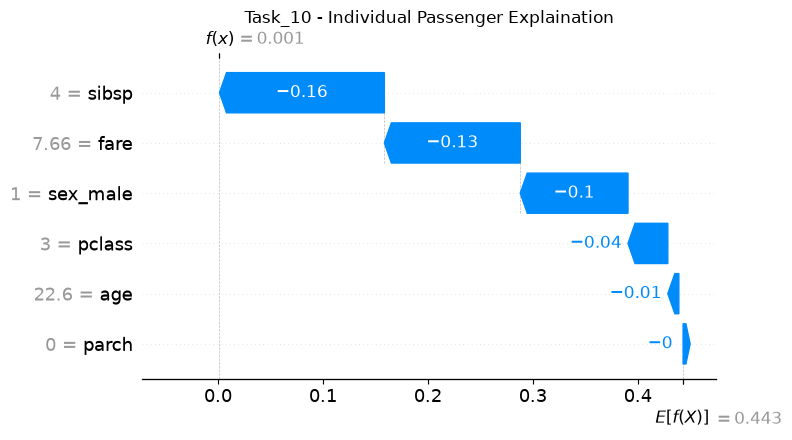


Feature contribution, strongest First : 


,Feature,Passenger value,SHAP contribution,Effect
3,sibsp,4.00,-0.1571,Lowered predicted survival probability
5,fare,7.66,-0.1295,Lowered predicted survival probability
1,sex_male,1.00,-0.1027,Lowered predicted survival probability
0,pclass,3.00,-0.0380,Lowered predicted survival probability
2,age,22.60,-0.0105,Lowered predicted survival probability
4,parch,0.00,-0.0041,Lowered predicted survival probability


### TASK 10 — Response to the Sceptical Reader

**Most confident incorrect prediction.** The actual outcome was **Did not survive**, while the model predicted **Did not survive** with 99.9% confidence. number of siblings or spouses aboard (value 4) pushed the predicted survival probability downward (SHAP contribution -0.157). ticket fare (value 7.66) pushed the predicted survival probability downward (SHAP contribution -0.129). sex (male = 1, female = 0) (value 1) pushed the predicted survival probability downward (SHAP contribution -0.103). These contributions explain the model's reasoning, but they do not guarantee what happened to an individual passenger. The model predicted non-survival, but the passenger survived. The passenger's contributing features collectively led the model to a survival probability below its 0.5 decision threshold. **Next step:** I would inspect this passenger's original record and compare similar passengers to check for data errors, missing context, or patterns the model has not learned.

In [52]:
# ============================================================
# TASK 10 — Explain a Prediction to a Sceptical Reader
# Titanic Survival Model + SHAP Waterfall Plot
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. Load the uploaded Titanic CSV file
# ------------------------------------------------------------

df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

print("Dataset loaded:", df)
print("Dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. Check columns and prepare the data
# ------------------------------------------------------------

required = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

for col in ["survived", "pclass", "age", "sibsp", "parch", "fare"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Encode sex: female = 0, male = 1
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower()
    .map({"male": 1, "female": 0})
)

# Fill missing age by passenger class, then overall median
df["age"] = df["age"].fillna(
    df.groupby("pclass")["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Remove rows without a usable target or essential feature
df = df.dropna(
    subset=["survived", "pclass", "sex_male", "age", "sibsp", "parch", "fare"]
)

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].astype(float)
y = df["survived"].astype(int)

# ------------------------------------------------------------
# 3. Split the data and train the XGBoost model
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

# ------------------------------------------------------------
# 4. Find the most confident wrong prediction
# ------------------------------------------------------------

# Probability of survival for every test passenger
probabilities = model.predict_proba(X_test)[:, 1]

# Convert probabilities to predicted classes using threshold 0.5
predictions = (probabilities >= 0.5).astype(int)

# Confidence is the probability assigned to the predicted class
confidence = np.maximum(probabilities, 1 - probabilities)

actual = y_test.to_numpy
wrong_mask = predictions != actual

if wrong_mask.any():
    # Select the wrong prediction with the highest confidence
    candidate_positions = np.where(wrong_mask)[0]
    selected_position = candidate_positions[
        np.argmax(confidence[candidate_positions])
    ]
    
    selection_note = "Most confident incorrect prediction"
    was_wrong = True
else:
    selected_position = int(np.argmax(confidence)) 
    selection_note = (
        "No incorrect test predictions; showing the most confident"
        "correct prediction instead"
    )   
    was_wrong = False
    
    
# Get the selected passenger's features and results
passenger_features = X_test.iloc[selected_position]
actual_label = int(y_test.iloc[selected_position])
predicated_label = int(predictions[selected_position])
survival_probability = float(probabilities[selected_position])
selected_confidence = float(confidence[selected_position])

actual_text = "Survived" if actual_label == 1 else "Did not survive"
predicted_text = "Survived" if predicated_label == 1 else "Did not survive"

print("\n--- Seleceted Passenger ---")
print(selection_note)

print("Test-set row position : ", selected_position)
print("Actual output : ", actual_text)
print("Model prediction : ", predicted_text)
print(f"Predicted survival probability : {survival_probability:.3f}")
print(f"Model confidence in its prediction : {selected_confidence:.3f}")

display(passenger_features.to_frame(name="Passenger feature values"))

# ------------------------------------------------------------
# 5. Calculate SHAP values and create the waterfall plot
# ------------------------------------------------------------

# Use a sample of training rows as the reference background
background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

explainer = shap.TreeExplainer(
    model,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

# Explain the test set; each row's SHAP values explain its
# predicted survival probability relative to the baseline.
shap_explanation = explainer(X_test)

# Waterfall plot for the selected passenger
print("\nSHAP Waterfall plot for the selected passenger:")
shap.plots.waterfall(
    shap_explanation[selected_position],
    max_display=len(feature),
    show=False
)
plt.title("Task_10 - Individual Passenger Explaination")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Print the strongest contributions for this passenger
# ------------------------------------------------------------

row_shap_values = np.asarray(
    shap_explanation.values[selected_position]
).reshape(-1)

contribution_table = pd.DataFrame({
    "Feature": features,
    "Passenger value": passenger_features.to_numpy(),
    "SHAP contribution": row_shap_values
})

contribution_table["Effect"] = np.where(
    contribution_table["SHAP contribution"] > 0,
    "Raised predicted survival probability",
    np.where(
        contribution_table["SHAP contribution"] < 0,
        "Lowered predicted survival probability",
        "Little or no effect"
    )
)

contribution_table["Absolute contribution"] = (
    contribution_table["SHAP contribution"].abs()
)

contribution_table = contribution_table.sort_values(
    "Absolute contribution", ascending=False
)

print("\nFeature contribution, strongest First : ")
display(
    contribution_table[
        ["Feature", "Passenger value", "SHAP contribution", "Effect"]
    ].round(4)
)
    
# ------------------------------------------------------------
# 7. Generate a short response to the sceptical reader
# ------------------------------------------------------------

top_contributors = contribution_table.head(3)
contribution_sentences = []

feature_names = {
    "pclass": "passenger class",
    "sex_male": "sex (male = 1, female = 0)",
    "age": "age",
    "sibsp": "number of siblings or spouses aboard",
    "parch": "number of parents or children aboard",
    "fare": "ticket fare"
}

for _, row in top_contributors.iterrows():
    feature = row["Feature"]
    value = row["Passenger value"]
    contribution = row["SHAP contribution"]
    name = feature_names.get(feature, feature)

    if contribution > 0:
        effect = "pushed the predicted survival probability upward"
    elif contribution < 0:
        effect = "pushed the predicted survival probability downward"
    else:
        effect = "had almost no effect on the prediction"

    contribution_sentences.append(
        f"{name} (value {value:g}) {effect} "
        f"(SHAP contribution {contribution:+.3f})."
    )

if was_wrong:
    if predicted_label == 1:
        error_reason = (
            "The model predicted survival, but the passenger did not survive. "
            "The passenger's contributing features collectively led the model "
            "to a survival probability above its 0.5 decision threshold."
        )
    else:
        error_reason = (
            "The model predicted non-survival, but the passenger survived. "
            "The passenger's contributing features collectively led the model "
            "to a survival probability below its 0.5 decision threshold."
        )

    next_step = (
        "I would inspect this passenger's original record and compare similar "
        "passengers to check for data errors, missing context, or patterns the "
        "model has not learned."
    )
else:
    error_reason = (
        "There were no incorrect predictions on this test set, so this example "
        "shows the most confident correct prediction instead."
    )

    next_step = (
        "I would inspect borderline and misclassified cases from a separate "
        "evaluation set to learn where the model is less reliable."
    )

paragraph = (
    f"**{selection_note}.** The actual outcome was **{actual_text}**, while "
    f"the model predicted **{predicted_text}** with "
    f"{selected_confidence:.1%} confidence. "
    + " ".join(contribution_sentences)
    + " These contributions explain the model's reasoning, but they do not "
      "guarantee what happened to an individual passenger. "
    + error_reason
    + " **Next step:** "
    + next_step
)

display(Markdown("### TASK 10 — Response to the Sceptical Reader\n\n" + paragraph))
    